<a href="https://colab.research.google.com/github/wadeea23/ECG-Based-Heartbeat-Classification-Using-Machine-Learning/blob/main/ECG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install wfdb

In [2]:
! pip install tensorflow

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import zipfile

zip_path = '/content/drive/MyDrive/GA/Capstone_GA/mitdb-1.0.0.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/mitdb-1.0.0')

In [58]:
import wfdb
import os
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split , GroupShuffleSplit
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, MaxPooling1D, Flatten
from sklearn.preprocessing import StandardScaler , LabelEncoder
import tensorflow as tf
import pandas as pd
from imblearn.over_sampling import SMOTE
import joblib

In [6]:
folder = '/content/mitdb-1.0.0/mit-bih-arrhythmia-database-1.0.0'

print(os.listdir(folder))

['208.atr', '121.hea', '203.at_', '117.at_', '121.atr', '202.xws', '222.xws', '209.at_', '102.hea', '102.xws', '213.atr', '124.xws', '114.atr', '111.dat', '105.xws', '111.atr', '109.hea', '215.dat', '203.dat', '203.xws', '230.atr', '111.hea', '219.hea', '223.dat', '117.xws', '100.xws', '221.xws', '210.xws', '234.hea', '106.hea', '122.xws', '119.hea', '114.xws', '233.hea', '228.dat', '108.hea', '112.hea', '202.atr', '223.xws', '220.xws', '222.at_', '201.dat', '222.dat', '214.dat', '203.at-', '212.xws', '200.xws', '102-0.atr', '115.xws', '116.dat', '117.dat', '207.hea', '208.hea', '201.xws', '219.xws', '122.hea', '228.xws', '214.hea', '108.at_', '217.hea', '121.dat', '112.dat', '233.xws', '220.dat', '214.xws', '232.xws', '114.dat', '207.atr', '200.hea', '219.dat', '108.atr', '109.xws', '105.hea', '217.xws', '108.xws', '228.hea', '101.dat', '109.dat', '201.hea', '213.dat', '215.xws', '100.atr', '116.hea', '109.atr', '202.hea', '234.atr', '212.hea', '231.hea', '233.dat', '118.hea', '234.xw

In [7]:
files = os.listdir(folder)

dat_count = str(files).count('.dat')
hea_count = str(files).count('.hea')
atr_count = str(files).count('.atr')

print("DAT:", dat_count)
print("HEA:", hea_count)
print("ATR:", atr_count)

DAT: 48
HEA: 48
ATR: 49


In [16]:
all_labels = []  # عشان اجوف كل الرموز اللي في الديتا سيت و شلون اخليهم مع بعض عقب
signals = []
for file in files:  # هاي الرموز ف ديتا سيت و صنفناهم  ع حسب المعيار العلمي

    if file.endswith('.hea'):

        name = file.replace('.hea', '')
        record = wfdb.rdrecord(folder + '/' + name)
        signal = record.p_signal[:, 0]
        signals.append(signal)
        annotation = wfdb.rdann(folder + '/' + name, 'atr')

        all_labels = all_labels + annotation.symbol

print("Signals:", len(signals))
print("Labels:", len(all_labels))
print("Label Types:", set(all_labels))


Signals: 48
Labels: 112647
Label Types: {'j', 'F', 'L', 'f', 'x', '!', '|', '"', 'R', '[', 'E', 'a', '/', '~', 'e', 'N', 'A', 'S', 'J', 'V', '+', ']', 'Q'}


In [10]:
# convert all clissy to aami in all records
N = all_labels.count('N') + all_labels.count('L') + all_labels.count('R') + all_labels.count('e') + all_labels.count('j')

S = all_labels.count('A') + all_labels.count('a') + all_labels.count('J') + all_labels.count('S')

V = all_labels.count('V') + all_labels.count('E')

F = all_labels.count('F')

Q = all_labels.count('/') + all_labels.count('f') + all_labels.count('Q')

print("N:", N)
print("S:", S)
print("V:", V)
print("F:", F)
print("Q:", Q)

N: 90631
S: 2781
V: 7236
F: 803
Q: 8043


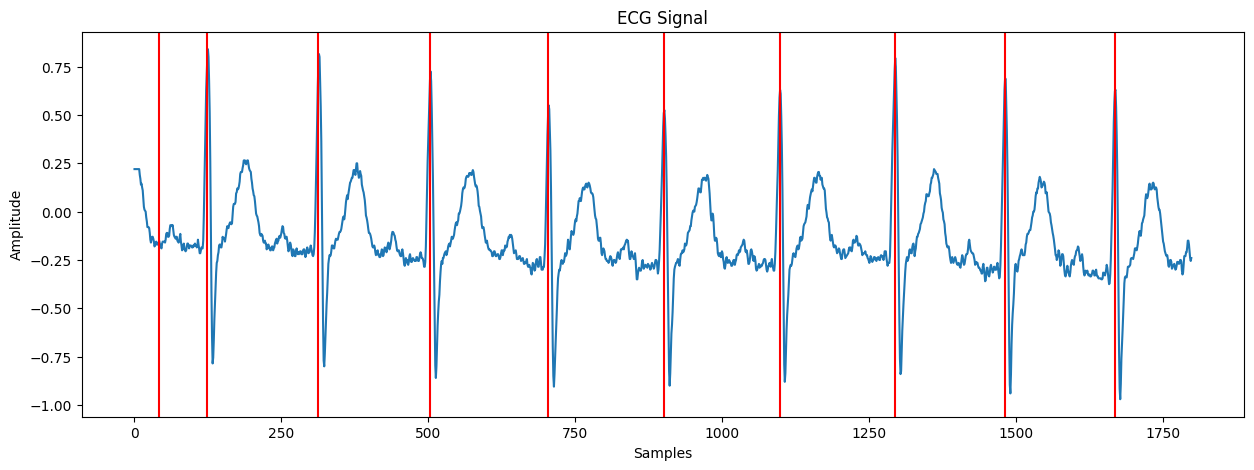

In [19]:
plt.figure(figsize=(15, 5))

plt.plot(signal[:1800]) # i choose 1800 / 360 hz = 5 sec

for peak in annotation.sample:
    if peak < 1800:
        plt.axvline(peak, color='red') # يحدد مكان النبض بالخطوط الطولية

plt.title('ECG Signal')
plt.xlabel('Samples')
plt.ylabel('Amplitude')
plt.show()

In [ ]:
# Heartbeat to prepare the data to train models

In [ ]:
# i will prapare the data to 48 record

In [21]:
X = []
y = []

for file in files:

    if file.endswith('.hea'):

        name = file.replace('.hea', '')

        record = wfdb.rdrecord(folder + '/' + name)
        annotation = wfdb.rdann(folder + '/' + name, 'atr')

        signal = record.p_signal[:, 0]

        for i in range(len(annotation.sample)):

            peak = annotation.sample[i]
            label = annotation.symbol[i]

            if label in ['N', 'L', 'R', 'e', 'j']:
                label = 'N'

            elif label in ['A', 'a', 'J', 'S']:
                label = 'S'

            elif label in ['V', 'E']:
                label = 'V'

            elif label != 'F':
                continue

            if peak >= 120 and peak + 240 <= len(signal):

                beat = signal[peak-120:peak+240]

                X.append(beat)
                y.append(label)

X = np.array(X)
y = np.array(y)

X = (X - X.mean(axis=1, keepdims=True)) / (X.std(axis=1, keepdims=True) + 0.00000001)

print("X Shape:", X.shape)
print("Y Shape:", y.shape)

X Shape: (101396, 360)
Y Shape: (101396,)


In [22]:
# model 1 split the data

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42,stratify=y_train)

In [ ]:
# model 1 binary classify 0=normal / 1=abnormal

In [24]:
y_train_binary = (y_train != 'N').astype(int) # to convert n to 0 other to 1
y_val_binary = (y_val != 'N').astype(int)
y_test_binary = (y_test != 'N').astype(int)

In [ ]:
# model 2 to classfy abnormal

In [25]:
X_train_2 = X_train[y_train != 'N'] # remove all normal
y_train_2 = y_train[y_train != 'N']

X_val_2 = X_val[y_val != 'N']
y_val_2 = y_val[y_val != 'N']

X_test_2 = X_test[y_test != 'N']
y_test_2 = y_test[y_test != 'N']

In [ ]:
## dt for bainary model

In [26]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train_binary)

pred = dt_model.predict(X_val)

print(classification_report(y_val_binary, pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      9058
           1       0.85      0.87      0.86      1082

    accuracy                           0.97     10140
   macro avg       0.92      0.93      0.92     10140
weighted avg       0.97      0.97      0.97     10140



In [27]:
pred = dt_model.predict(X_test)

print(classification_report(y_test_binary, pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     18117
           1       0.86      0.87      0.87      2163

    accuracy                           0.97     20280
   macro avg       0.92      0.93      0.92     20280
weighted avg       0.97      0.97      0.97     20280



In [ ]:
# knn model

In [28]:
scaler = StandardScaler()   # preprocessing
X_train_scaler = scaler.fit_transform(X_train)
X_val_scaler = scaler.transform(X_val)
X_test_scaler = scaler.transform(X_test)

In [29]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaler, y_train_binary)

knn_pred = knn_model.predict(X_val_scaler)

print(classification_report(y_val_binary, knn_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      9058
           1       0.96      0.91      0.94      1082

    accuracy                           0.99     10140
   macro avg       0.98      0.95      0.97     10140
weighted avg       0.99      0.99      0.99     10140



In [30]:
pred = knn_model.predict(X_test_scaler)

print(classification_report(y_test_binary, pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99     18117
           1       0.96      0.91      0.93      2163

    accuracy                           0.99     20280
   macro avg       0.97      0.95      0.96     20280
weighted avg       0.99      0.99      0.99     20280



In [ ]:
# cnn model

In [31]:
X_train_cnn = X_train.reshape(-1, 360, 1)
X_val_cnn = X_val.reshape(-1, 360, 1)
X_test_cnn = X_test.reshape(-1, 360, 1)

cnn_model = Sequential()

cnn_model.add(Conv1D(32, 3, activation='relu', input_shape=(360, 1)))
cnn_model.add(MaxPooling1D(2))

cnn_model.add(Conv1D(64, 3, activation='relu'))
cnn_model.add(MaxPooling1D(2))

cnn_model.add(Flatten())

cnn_model.add(Dense(64, activation='relu'))
cnn_model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [32]:
cnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])


In [33]:
cnn_model.fit(X_train_cnn, y_train_binary, epochs=10, validation_data=(X_val_cnn, y_val_binary))


Epoch 1/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 40s 17ms/step - accuracy: 0.9733 - loss: 0.0909 - val_accuracy: 0.9834 - val_loss: 0.0572
Epoch 2/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 40s 17ms/step - accuracy: 0.9851 - loss: 0.0492 - val_accuracy: 0.9821 - val_loss: 0.0576
Epoch 3/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 54s 24ms/step - accuracy: 0.9892 - loss: 0.0366 - val_accuracy: 0.9866 - val_loss: 0.0458
Epoch 4/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 67s 30ms/step - accuracy: 0.9911 - loss: 0.0291 - val_accuracy: 0.9899 - val_loss: 0.0382
Epoch 5/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 58s 20ms/step - accuracy: 0.9926 - loss: 0.0230 - val_accuracy: 0.9884 - val_loss: 0.0425
Epoch 6/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 39s 17ms/step - accuracy: 0.9936 - loss: 0.0187 - val_accuracy: 0.9886 - val_loss: 0.0398
Epoch 7/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 39s 18ms/step - accuracy: 0.9946 - loss: 0.0154 - val_accuracy: 0.9894 - val_loss: 0.0399
Epoch 8/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 40s 17ms/step - accuracy: 0.9955 -

In [34]:
pred = (cnn_model.predict(X_val_cnn) > 0.5).astype(int)

print(classification_report(y_val_binary, pred))

317/317 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      9058
           1       0.97      0.93      0.95      1082

    accuracy                           0.99     10140
   macro avg       0.98      0.96      0.97     10140
weighted avg       0.99      0.99      0.99     10140



In [35]:
cnn_pred = (cnn_model.predict(X_test_cnn) > 0.5).astype(int)

print(classification_report(y_test_binary, cnn_pred))

634/634 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     18117
           1       0.96      0.94      0.95      2163

    accuracy                           0.99     20280
   macro avg       0.98      0.97      0.97     20280
weighted avg       0.99      0.99      0.99     20280



In [36]:
best_model=cnn_model
best_model.save('best_bainary_model.keras')

In [37]:
best_model = tf.keras.models.load_model('best_bainary_model.keras')

In [ ]:
# model 2 to clissfy abnormal

In [ ]:
# dt2

In [38]:
dt2_model = DecisionTreeClassifier(random_state=42)

dt2_model.fit(X_train_2, y_train_2)

dt2_pred = dt2_model.predict(X_val_2)

print(classification_report(y_val_2, dt2_pred))

              precision    recall  f1-score   support

           F       0.78      0.78      0.78        80
           S       0.94      0.94      0.94       278
           V       0.96      0.96      0.96       724

    accuracy                           0.94      1082
   macro avg       0.89      0.89      0.89      1082
weighted avg       0.94      0.94      0.94      1082



In [ ]:
# knn2

In [43]:
scaler2 = StandardScaler()

X_train_scaled = scaler2.fit_transform(X_train_2)
X_val_scaled = scaler2.transform(X_val_2)

In [44]:
knn2_model = KNeighborsClassifier(n_neighbors=5)

knn2_model.fit(X_train_scaled, y_train_2)

knn2_pred = knn2_model.predict(X_val_scaled)

print(classification_report(y_val_2, knn2_pred))

              precision    recall  f1-score   support

           F       0.86      0.84      0.85        80
           S       0.96      0.93      0.95       278
           V       0.96      0.98      0.97       724

    accuracy                           0.96      1082
   macro avg       0.93      0.92      0.92      1082
weighted avg       0.96      0.96      0.96      1082



In [ ]:
#cnn2

In [45]:
X_train_cnn2 = X_train_2.reshape(-1, 360, 1)
X_val_cnn2 = X_val_2.reshape(-1, 360, 1)
X_test_cnn2 = X_test_2.reshape(-1, 360, 1)

In [46]:
encoder2 = LabelEncoder()

y_train_encoded = encoder2.fit_transform(y_train_2)
y_val_encoded = encoder2.transform(y_val_2)
y_test_encoded = encoder2.transform(y_test_2)

In [47]:
class_names = {
    'F': 'Fusion Beat',
    'S': 'Supraventricular Ectopic Beat',
    'V': 'Ventricular Ectopic Beat'
}

In [48]:
cnn2_model = Sequential()

cnn2_model.add(Conv1D(32, 3, activation='relu', input_shape=(360, 1)))
cnn2_model.add(MaxPooling1D(2))

cnn2_model.add(Conv1D(64, 3, activation='relu'))
cnn2_model.add(MaxPooling1D(2))

cnn2_model.add(Flatten())

cnn2_model.add(Dense(64, activation='relu'))
cnn2_model.add(Dense(3, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [49]:
cnn2_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [50]:
history2 = cnn2_model.fit(X_train_cnn2,y_train_encoded,epochs=20,batch_size=32,validation_data=(X_val_cnn2, y_val_encoded)
)

Epoch 1/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9392 - loss: 0.1782 - val_accuracy: 0.9630 - val_loss: 0.1146
Epoch 2/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.9678 - loss: 0.1000 - val_accuracy: 0.9658 - val_loss: 0.1031
Epoch 3/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9750 - loss: 0.0750 - val_accuracy: 0.9704 - val_loss: 0.0993
Epoch 4/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9794 - loss: 0.0576 - val_accuracy: 0.9667 - val_loss: 0.1081
Epoch 5/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.9824 - loss: 0.0453 - val_accuracy: 0.9750 - val_loss: 0.0963
Epoch 6/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9875 - loss: 0.0359 - val_accuracy: 0.9704 - val_loss: 0.1071
Epoch 7/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9886 - loss: 0.0311 - val_accuracy: 0.9667 - val_loss: 0.1159
Epoch 8/20
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.9904 - loss: 0.0254 - val_accu

In [51]:
cnn2_pred = cnn2_model.predict(X_val_cnn2)

cnn2_pred = np.argmax(cnn2_pred, axis=1)

predicted_labels = encoder2.inverse_transform(cnn2_pred)

full_names = [class_names[label] for label in predicted_labels]

print(full_names[:10])

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
['Supraventricular Ectopic Beat', 'Ventricular Ectopic Beat', 'Supraventricular Ectopic Beat', 'Supraventricular Ectopic Beat', 'Supraventricular Ectopic Beat', 'Ventricular Ectopic Beat', 'Ventricular Ectopic Beat', 'Supraventricular Ectopic Beat', 'Ventricular Ectopic Beat', 'Ventricular Ectopic Beat']


In [68]:
print(classification_report(y_val_encoded, cnn2_pred,target_names=encoder2.classes_))

              precision    recall  f1-score   support

           F       0.93      0.81      0.87        80
           S       0.97      0.98      0.98       278
           V       0.98      0.99      0.98       724

    accuracy                           0.97      1082
   macro avg       0.96      0.93      0.94      1082
weighted avg       0.97      0.97      0.97      1082



In [67]:
cnn2_test_pred = cnn2_model.predict(X_test_cnn2)

cnn2_test_pred = np.argmax(cnn2_test_pred, axis=1)

print(classification_report(y_test_encoded, cnn2_test_pred,target_names=encoder2.classes_))

68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
              precision    recall  f1-score   support

           F       0.94      0.82      0.88       160
           S       0.98      0.97      0.98       556
           V       0.97      0.99      0.98      1447

    accuracy                           0.97      2163
   macro avg       0.96      0.93      0.94      2163
weighted avg       0.97      0.97      0.97      2163



In [56]:
cnn2_model.save('cnn2_model.keras')

In [60]:
joblib.dump(encoder2, 'encoder2.pkl')

['encoder2.pkl']